# 02 - One-factor price model: derivation, calibration, simulation

The storage contract is valued under a one-factor mean-reverting model of the TTF spot price that
reproduces today's forward curve exactly (Schwartz, 1997; Lucia & Schwartz, 2002 for the seasonal
version). This notebook

1. derives the implied forward $F(t,T)$ and proves that it is a martingale,
2. checks both martingale properties by Monte Carlo on the EEX curve of 2026-11-17,
3. calibrates $\kappa$ and $\sigma$ on TTF history (AR(1)-OLS and exact MLE, with standard errors) over
   several windows, and discusses the measure and window choices,
4. simulates spot paths over storage year 2027/28.

All code lives in `gasstorage.models`; the notebook only calls it.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir("..")

from gasstorage import plotting
from gasstorage.config import load_config
from gasstorage.data.forward_curve import ForwardCurve
from gasstorage.data.ttf import get_ttf_history
from gasstorage.models.calibration import calibrate_one_factor, calibrate_windows, fit_ou_ols
from gasstorage.models.one_factor import OneFactorModel
from gasstorage.timegrid import year_fraction

plotting.apply_style()
cfg = load_config("configs/storage_default.yaml")
c = cfg.contract
curve = ForwardCurve.from_config(cfg.market.forward_curve, c.start_date, c.end_date)
SEED = 2026

## 1. Model and implied forward

$$\ln S_t = \ln F(0,t) + X_t - \tfrac12 V(0,t),\qquad dX_t = -\kappa X_t\,dt + \sigma\,dW_t,\quad X_0=0,$$

$$V(t,T) := \operatorname{Var}(X_T\mid X_t) = \frac{\sigma^2}{2\kappa}\big(1-e^{-2\kappa(T-t)}\big).$$

**Solution of the OU equation.** Applying Itô to $e^{\kappa u}X_u$ gives $d(e^{\kappa u}X_u) = \sigma e^{\kappa u}dW_u$, hence for $t\le T$

$$X_T = e^{-\kappa(T-t)}X_t + \sigma\int_t^T e^{-\kappa(T-u)}\,dW_u .$$

The stochastic integral is independent of $\mathcal F_t$, Gaussian, centred, with variance (Itô isometry)
$\sigma^2\int_t^T e^{-2\kappa(T-u)}du = V(t,T)$. So $X_T\mid\mathcal F_t \sim \mathcal N\big(e^{-\kappa(T-t)}X_t,\ V(t,T)\big)$.
With $t=0$: $X_T\sim\mathcal N(0, V(0,T))$ and $\mathbb E[e^{X_T}] = e^{V(0,T)/2}$, so $\mathbb E[S_T] = F(0,T)$:
**the model reproduces the forward curve.**

**Implied forward.** Under the pricing measure the forward is the conditional expectation of the spot at delivery.
Using $\mathbb E[e^{Z}] = e^{m + v/2}$ for $Z\sim\mathcal N(m,v)$:

$$F(t,T) = \mathbb E_t[S_T] = F(0,T)\,e^{-\frac12 V(0,T)}\,\mathbb E_t\big[e^{X_T}\big]
= F(0,T)\exp\!\Big(e^{-\kappa(T-t)}X_t + \tfrac12 V(t,T) - \tfrac12 V(0,T)\Big).$$

**Martingale property.** $F(t,T)$ is a conditional expectation of a fixed random variable, so it is a martingale by the
tower property. Directly: $e^{-\kappa(T-t)}X_t\sim\mathcal N\big(0,\ e^{-2\kappa(T-t)}V(0,t)\big)$, so

$$\mathbb E[F(t,T)] = F(0,T)\exp\!\Big(\tfrac12\big[e^{-2\kappa(T-t)}V(0,t) + V(t,T) - V(0,T)\big]\Big) = F(0,T),$$

because $e^{-2\kappa(T-t)}\big(1-e^{-2\kappa t}\big) + 1 - e^{-2\kappa(T-t)} = 1 - e^{-2\kappa T}$.
At $t=T$, $V(T,T)=0$ and $F(T,T)=S_T$.

**Forward volatility.** $\ln F(t,T)$ has instantaneous volatility $\sigma e^{-\kappa(T-t)}$: far contracts move
much less than the spot (Samuelson effect). With a half-life of a few weeks, the winter contracts seen from April are
far less volatile than the spot; this is what limits the extrinsic value.

## 2. Monte Carlo check of the martingale properties

Exact simulation $X_{t_{i+1}} = e^{-\kappa\Delta_i}X_{t_i} + \sqrt{V(t_i,t_{i+1})}\,Z_i$, seed fixed, 200,000 paths,
calibrated parameters of the configuration (section 3). The test statistic is
$z = (\bar S - F)/\mathrm{SE}$ with $\mathrm{SE} = \hat s/\sqrt N$; $|z|<3$ is required.
In the second table all maturities share the same draws of $X_t$, so their $z$-scores are strongly correlated (for far
maturities $F(t,T)$ is nearly linear in the same $X_t$): they are one test, not twelve. The column `std F(t,T)` shows the
Samuelson effect: seen from 1 April 2027, the March 2028 forward has a standard deviation of about 0.12 EUR/MWh against
13 for April 2027.

In [2]:
model = OneFactorModel.from_config(cfg.model)
print(f"kappa = {model.kappa}, sigma = {model.sigma}")
mid_months = pd.DatetimeIndex([m.start_time + pd.Timedelta(days=14) for m in curve.months])
mid_months = mid_months[
    (mid_months >= pd.Timestamp(c.start_date)) & (mid_months <= pd.Timestamp(c.end_date))
]
tau = year_fraction(cfg.market.valuation_date, mid_months)
fwd = curve.daily(mid_months)
n = 200_000
s = model.spot(model.simulate_x(tau, n, np.random.default_rng(SEED)), tau, fwd)
mean, se = s.mean(axis=1), s.std(axis=1, ddof=1) / np.sqrt(n)
spot_check = pd.DataFrame(
    {"F(0,t)": fwd, "MC mean S_t": mean, "SE": se, "z": (mean - fwd) / se},
    index=mid_months.date,
)
print(f"max |z| = {spot_check['z'].abs().max():.2f}")
spot_check.round(3)

kappa = 4.784, sigma = 0.694
max |z| = 0.87


,"F(0,t)",MC mean S_t,SE,z
2027-04-15,71.221,71.233,0.036,0.344
2027-05-15,66.937,66.954,0.034,0.502
2027-06-15,64.975,64.973,0.033,-0.070
2027-07-15,63.873,63.891,0.032,0.568
2027-08-15,63.240,63.225,0.032,-0.465
2027-09-15,62.688,62.689,0.032,0.016
2027-10-15,60.446,60.456,0.031,0.333
2027-11-15,60.162,60.153,0.031,-0.301
2027-12-15,59.962,59.956,0.030,-0.206
2028-01-15,57.770,57.773,0.029,0.089


In [3]:
t_obs = year_fraction(cfg.market.valuation_date, pd.DatetimeIndex([c.start_date]))[0]
x_t = model.simulate_x([t_obs], n, np.random.default_rng(SEED + 1))[0]
rows = {}
for d, T, F0T in zip(mid_months.date, tau, fwd, strict=True):
    f = model.forward(x_t, t_obs, T, F0T)
    m, e = f.mean(), f.std(ddof=1) / np.sqrt(n)
    rows[d] = {
        "F(0,T)": F0T,
        "MC mean F(t,T)": m,
        "SE": e,
        "z": (m - F0T) / e,
        "std F(t,T)": f.std(),
    }
fwd_check = pd.DataFrame.from_dict(rows, orient="index")
print(f"t = {c.start_date} (tau = {t_obs:.3f} y); max |z| = {fwd_check['z'].abs().max():.2f}")
fwd_check.round(3)

t = 2027-04-01 (tau = 0.370 y); max |z| = 0.68


,"F(0,T)","MC mean F(t,T)",SE,z,"std F(t,T)"
2027-04-15,71.221,71.201,0.030,-0.678,13.200
2027-05-15,66.937,66.925,0.019,-0.663,8.337
2027-06-15,64.975,64.967,0.012,-0.654,5.380
2027-07-15,63.873,63.868,0.008,-0.649,3.567
2027-08-15,63.240,63.237,0.005,-0.646,2.352
2027-09-15,62.688,62.686,0.003,-0.645,1.552
2027-10-15,60.446,60.445,0.002,-0.643,1.010
2027-11-15,60.162,60.161,0.001,-0.643,0.670
2027-12-15,59.962,59.961,0.001,-0.642,0.451
2028-01-15,57.770,57.770,0.001,-0.642,0.289


## 3. Calibration on TTF history

**Data and decomposition.** Daily TTF front-month closes (Yahoo `TTF=F`). On each window the log-price is split into
a deterministic part $f(t) = a + bt + \sum_{k=1}^{2}(c_k\cos 2\pi kt + d_k\sin 2\pi kt)$ (OLS) and a residual $Y_t$
modelled as an OU process. Observation step $\Delta = 1/252$ (trading days).

**Estimators** (formulas in `gasstorage.models.calibration`): AR(1) regression $Y_{i+1} = \alpha + \phi Y_i + \varepsilon_i$
with $\hat\kappa = -\ln\hat\phi/\Delta$, $\hat\sigma = \hat s\sqrt{2\hat\kappa/(1-\hat\phi^2)}$ and delta-method standard
errors; then the exact Gaussian MLE, with standard errors from the inverse numerical Hessian.

**Reference window (decided): post-crisis, 2023-04-01 to the last observation.**

In [4]:
ttf = get_ttf_history()
ref = calibrate_one_factor(ttf, "2023-04-01", None, n_harmonics=2, trend=True, method="mle")
ols = fit_ou_ols(ref.residuals.to_numpy())
est = ref.estimate
pd.DataFrame(
    {
        "OLS": [ols.kappa, ols.se_kappa, ols.sigma, ols.se_sigma, ols.half_life_days, ols.df_tstat],
        "MLE": [est.kappa, est.se_kappa, est.sigma, est.se_sigma, est.half_life_days, est.df_tstat],
    },
    index=[
        "kappa (1/y)",
        "se kappa",
        "sigma (1/sqrt y)",
        "se sigma",
        "half-life (days)",
        "DF t-stat",
    ],
).round(3)

,OLS,MLE
kappa (1/y),4.784,4.784
se kappa,1.587,1.585
sigma (1/sqrt y),0.695,0.694
se sigma,0.016,0.016
half-life (days),52.881,52.881
DF t-stat,-3.044,-3.044


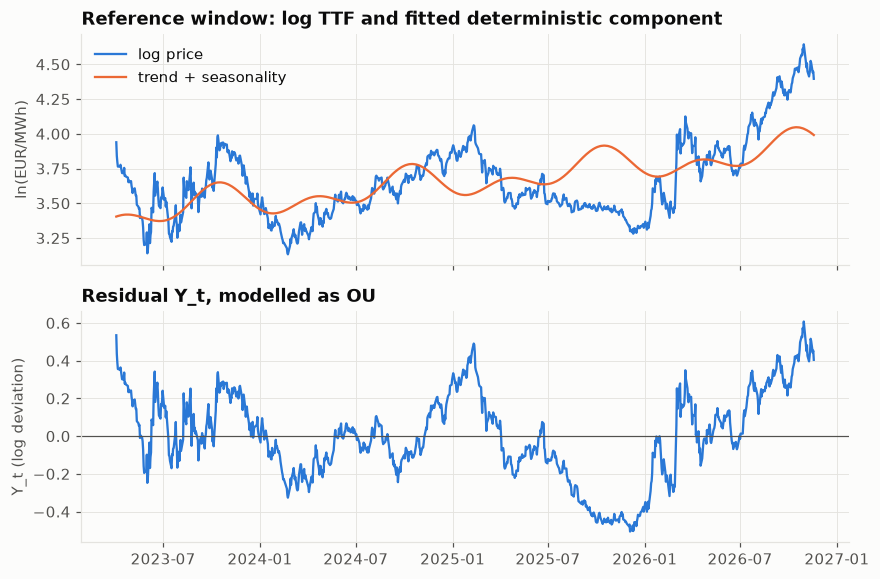

In [5]:
w = ttf.loc["2023-04-01":]
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(w.index, np.log(w.to_numpy()), color=plotting.SERIES[0], label="log price")
axes[0].plot(
    w.index, ref.seasonal.evaluate(w.index), color=plotting.SERIES[1], label="trend + seasonality"
)
axes[0].set_ylabel("ln(EUR/MWh)")
axes[0].set_title("Reference window: log TTF and fitted deterministic component")
axes[0].legend(loc="upper left")
axes[1].plot(ref.residuals.index, ref.residuals.to_numpy(), color=plotting.SERIES[0])
axes[1].axhline(0, color=plotting.TEXT_SECONDARY, lw=0.8)
axes[1].set_ylabel("Y_t (log deviation)")
axes[1].set_title("Residual Y_t, modelled as OU")
plotting.save_figure(fig, "02_calibration_reference")
fig

**Sensitivity to the window.** Full sample with the three stress episodes flagged, and sub-windows that
isolate them: the 2020 price collapse (inside the pre-crisis window), the 2021-07 to 2023-03 supply crisis, and the
2026 rally (reference window with and without 2026). Each window is calibrated with and without the linear trend.

In [6]:
windows = {
    "post-crisis 2023-04.. (ref)": ("2023-04-01", None),
    "post-crisis excl. 2026 rally": ("2023-04-01", "2025-12-31"),
    "full sample": (None, None),
    "pre-crisis incl. 2020 collapse": (None, "2021-06-30"),
    "crisis 2021-07..2023-03": ("2021-07-01", "2023-03-31"),
}
cols = ["n_obs", "kappa", "se_kappa", "sigma", "se_sigma", "half_life_days", "df_tstat", "note"]
table = pd.concat(
    {
        "trend": calibrate_windows(ttf, windows, trend=True)[cols],
        "no trend": calibrate_windows(ttf, windows, trend=False)[cols],
    }
)
table.round(3)

n_obs  kappa  se_kappa  sigma  \
trend    post-crisis 2023-04.. (ref)       914  4.784     1.585  0.694   
         post-crisis excl. 2026 rally      692  7.390     2.277  0.654   
         full sample                      2283  0.705     0.395  0.793   
         pre-crisis incl. 2020 collapse    928    NaN       NaN    NaN   
         crisis 2021-07..2023-03           441  3.602     2.084  1.226   
no trend post-crisis 2023-04.. (ref)       914  2.705     1.358  0.693   
         post-crisis excl. 2026 rally      692  7.383     2.271  0.654   
         full sample                      2283  0.522     0.340  0.793   
         pre-crisis incl. 2020 collapse    928  0.230     0.740  0.609   
         crisis 2021-07..2023-03           441  3.999     1.945  1.225   

                                         se_sigma  half_life_days  df_tstat  \
trend    post-crisis 2023-04.. (ref)        0.016          52.881    -3.044   
         post-crisis excl. 2026 rally       0.018          34.236    -3.289   
         full sample                        0.012         358.889    -1.786   
         pre-crisis incl. 2020 collapse       NaN             NaN     0.177   
         crisis 2021-07..2023-03            0.042          70.244    -1.737   
no trend post-crisis 2023-04.. (ref)        0.016          93.543    -2.000   
         post-crisis excl. 2026 rally       0.018          34.266    -3.295   
         full sample                        0.012         484.443    -1.538   
         pre-crisis incl. 2020 collapse     0.014        1099.609    -0.311   
         crisis 2021-07..2023-03            0.042          63.272    -2.067   

                                                                     note  
trend    post-crisis 2023-04.. (ref)                                       
         post-crisis excl. 2026 rally                                      
         full sample                                                       
         pre-crisis incl. 2020 collapse  no mean reversion (phi = 1.0006)  
         crisis 2021-07..2023-03                                           
no trend post-crisis 2023-04.. (ref)                                       
         post-crisis excl. 2026 rally                                      
         full sample                                                       
         pre-crisis incl. 2020 collapse                                    
         crisis 2021-07..2023-03

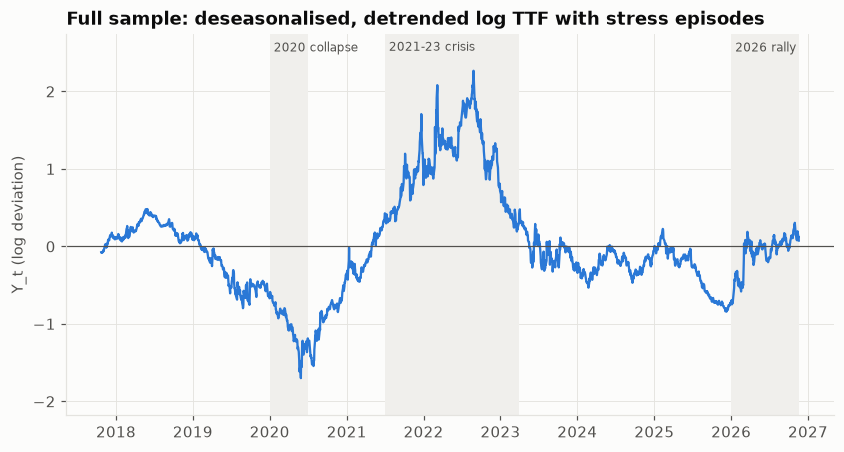

In [7]:
full = calibrate_one_factor(ttf, None, None, trend=True)
episodes = {
    "2020 collapse": ("2020-01-01", "2020-06-30"),
    "2021-23 crisis": ("2021-07-01", "2023-03-31"),
    "2026 rally": ("2026-01-01", str(ttf.index.max().date())),
}
fig, ax = plt.subplots()
for name, (a, b) in episodes.items():
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=plotting.NEUTRAL_FILL, lw=0)
    ax.text(
        pd.Timestamp(a),
        0.98,
        " " + name,
        transform=ax.get_xaxis_transform(),
        va="top",
        fontsize=8,
        color=plotting.TEXT_SECONDARY,
    )
ax.plot(full.residuals.index, full.residuals.to_numpy(), color=plotting.SERIES[0])
ax.axhline(0, color=plotting.TEXT_SECONDARY, lw=0.8)
ax.margins(y=0.12)
ax.set_ylabel("Y_t (log deviation)")
ax.set_title("Full sample: deseasonalised, detrended log TTF with stress episodes")
plotting.save_figure(fig, "02_residuals_full_sample")
fig

**Reading the table.**

* $\sigma$ is sharply identified (standard error about 2 % of the estimate) and stable at 0.65-0.69 outside the crisis;
  the crisis window doubles it (about 1.23).
* $\kappa$ is poorly identified from daily data: on the reference window $\hat\kappa = 4.8 \pm 1.6$ per year
  (half-life about 53 days). The Dickey-Fuller statistics rarely clear the asymptotic 5 % critical values
  (about $-2.86$ with a constant, $-3.41$ with a trend; MacKinnon, 2010): daily mean reversion is weak relative to
  noise over a few years, a well-known feature of commodity prices. Over the full sample, level shifts between regimes
  (2020 collapse, crisis, 2026 rally) are absorbed by $X$ and pull $\kappa$ towards zero; on the pre-crisis window with a
  trend no mean reversion is detected at all ($\hat\phi > 1$).
* The linear trend matters: without it the reference $\kappa$ falls to about 2.7. The trend is kept in the reference
  calibration because the one-factor $X$ is meant to capture *short-term* deviations; slow level drift is the job of a
  long-term factor (Schwartz-Smith extension, Phase 7), and in pricing the level is set by the forward curve anyway.
* Consequence for valuation: $\kappa$ is the main parameter uncertainty. Its effect on the storage value is measured
  in Phase 6 (sensitivity to $\kappa$) rather than hidden.

**Historical vs risk-neutral measure.** The estimates are under $\mathbb P$. Pricing needs $\mathbb Q$. With a constant
market price of risk $\lambda$, Girsanov turns $dX = -\kappa X dt + \sigma dW^{\mathbb P}$ into an OU with the *same*
$\kappa,\sigma$ and a shifted mean, and that shift is absorbed when the model is fitted to $F(0,t)$. The remaining gaps:
risk premia vary in time (especially in crises); the market-implied volatility of TTF options can differ from the
historical one; and the front-month future is only a proxy for the spot (it has no seasonal delivery shape and rolls
monthly). A desk would calibrate $\sigma$ to option prices; without free option data, the historical estimate and a
sensitivity analysis are used here.

**Is the market price of risk constant? No, and this matters for $\kappa$, not for $\sigma$.** Girsanov changes the
drift, never the diffusion coefficient, so $\sigma$ is the same under $\mathbb P$ and $\mathbb Q$ whatever the risk
premium. $\kappa$ is invariant only if the premium is constant. If it depends on the state, e.g.
$\lambda_t = \lambda_0 + \lambda_1 X_t$, then under $\mathbb Q$

$$dX_t = \big(-(\kappa + \sigma\lambda_1)X_t - \sigma\lambda_0\big)\,dt + \sigma\,dW_t^{\mathbb Q},
\qquad \kappa_{\mathbb Q} = \kappa_{\mathbb P} + \sigma\lambda_1 .$$

Empirically, commodity futures risk premia vary over time and with inventories (Fama & French, 1987; Gorton, Hayashi &
Rouwenhorst, 2013; Bessembinder & Lemmon, 2002 for power), and 2026, with low European stocks, is unlikely to be a
"constant premium" year. Fitting $F(0,t)$ absorbs only today's deterministic premium, not its dynamics.

*How $\kappa_{\mathbb Q}$ could be measured.* Under the model, $d\ln F(t,T)$ has volatility
$\sigma e^{-\kappa_{\mathbb Q}(T-t)}$, and realised volatility is measure-invariant. The decay of realised volatility
across contracts M+1, M+2, ..., M+6 therefore identifies $\kappa_{\mathbb Q}$ directly. This needs a history of
several maturities (not available from Yahoo, which only provides the front month) and is listed as an extension.
Until then, $\kappa$ is the parameter whose valuation sensitivity is reported explicitly (Phase 6).

## 4. Simulated spot over storage year 2027/28

Daily exact simulation from the valuation date (2026-11-17) to 2028-03-31 on the EEX curve. The fan narrows towards
the curve only through mean reversion of $X$; its width reflects the stationary standard deviation
$\sigma/\sqrt{2\kappa}$.

stationary sd of X: 0.224


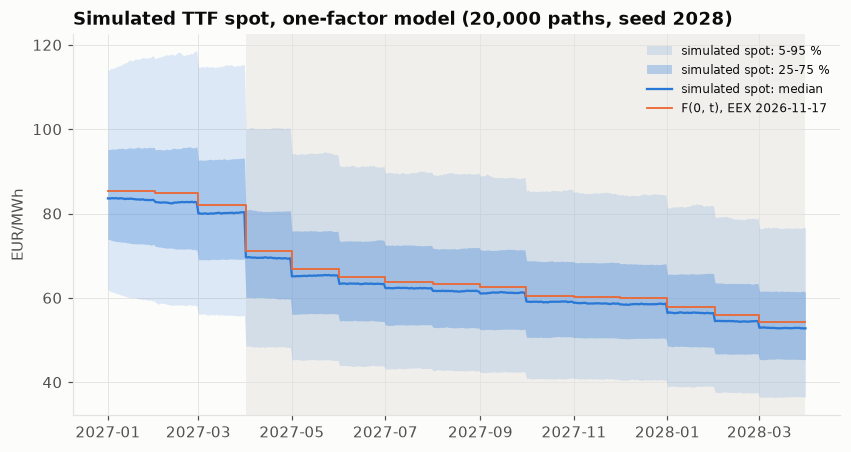

In [8]:
days = pd.date_range(
    pd.Timestamp(cfg.market.valuation_date) + pd.Timedelta(days=1), c.end_date, freq="D"
)
days = days[days >= pd.Timestamp(curve.months[0].start_time)]
tau_d = year_fraction(cfg.market.valuation_date, days)
paths = model.spot(
    model.simulate_x(tau_d, 20_000, np.random.default_rng(SEED + 2)), tau_d, curve.daily(days)
)
fig, ax = plt.subplots()
plotting.fan_chart(ax, days, paths, label="simulated spot")
ax.step(
    days,
    curve.daily(days),
    where="post",
    color=plotting.SERIES[1],
    lw=1.2,
    label="F(0, t), EEX 2026-11-17",
)
ax.axvspan(
    pd.Timestamp(c.start_date),
    pd.Timestamp(c.end_date),
    color=plotting.NEUTRAL_FILL,
    lw=0,
    zorder=0,
)
ax.set_ylabel("EUR/MWh")
ax.set_title("Simulated TTF spot, one-factor model (20,000 paths, seed 2028)")
ax.legend(loc="upper right", fontsize=8)
plotting.save_figure(fig, "02_spot_fan")
print(f"stationary sd of X: {model.sigma / np.sqrt(2 * model.kappa):.3f}")
fig